# Предварительный анализ данных NTNU

Данные содержат записи инерциальных датчиков людей с протезами нижних конечностей. Цель этого этапа — проверить состав файлов, разметку `Terrain` и пригодность циклов шага для классификации поверхности.

В [Wassall et al. (2026)](https://doi.org/10.1371/journal.pone.0358882) использовались записи 20 участников. Здесь анализируются доступные CSV без исправления исходных файлов.

## 1. Библиотеки и пути


In [1]:
from pathlib import Path
import hashlib
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

from research_graph.paths import NTNU_DIR, report_dir
from research_graph.pipelines.preprocessing import SAMPLING_HZ, SOURCE_CHANNELS

DATA_DIR = NTNU_DIR
OUTPUT_DIR = report_dir("eda_ntnu_notebook")
SAVE_ARTIFACTS = False
FS = SAMPLING_HZ  # Частота из описания авторов; в CSV временных меток нет.

TERRAIN_NAMES = {
    1: "Ровная поверхность", 2: "Трава", 4: "Лестница вверх",
    5: "Лестница вниз", 6: "Подъём", 7: "Спуск",
    8: "Код 8 (название спорное)", 9: "Код 9 (название спорное)",
}
SENSORS = ("PS", "TH", "OS", "TR")
CHANNELS = list(SOURCE_CHANNELS)
REQUIRED = CHANNELS + ["Steps", "Terrain", "Turn"]

if SAVE_ARTIFACTS:
    (OUTPUT_DIR / "tables").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

print("Папка с данными:", DATA_DIR)
print("Существует:", DATA_DIR.is_dir())

Папка с данными: ~/research-publication-data\data\raw\ntnu
Существует: True


In [2]:
paths = sorted(DATA_DIR.glob("*/*.csv"))
if not paths:
    raise FileNotFoundError(f"Не найдены CSV в {DATA_DIR}. Проверьте структуру папок.")

pattern = re.compile(r"(?P<route>[A-Za-z]+?)(?P<aid>wi|wo|w0)(?P<repeat>\d+)(?P<sensor>PS|TH|OS|TR|OH)$", re.I)
file_info = []
for path in paths:
    match = pattern.fullmatch(path.stem)
    if match is None:
        raise ValueError(f"Неизвестный формат имени: {path.name}")
    parts = match.groupdict()
    # Номер повторения без ведущих нулей нужен только для группировки.
    trial = f"{parts['route'].upper()}_{parts['aid'].lower()}_{int(parts['repeat'])}"
    file_info.append({"participant": path.parent.name, "trial": trial,
                      "sensor": parts["sensor"].upper(), "route": parts["route"].upper(),
                      "aid": parts["aid"].lower(), "path": path})

inventory = pd.DataFrame(file_info)
by_person = inventory.groupby("participant").agg(
    files=("path", "size"), trials=("trial", "nunique"), sensors=("sensor", "nunique")
).reset_index()
display(by_person)
print(f"Участников: {len(by_person)}, файлов: {len(inventory)}, "
      f"комплектов по именам: {inventory.groupby(['participant', 'trial']).ngroups}")
print("Типы датчиков:", sorted(inventory.sensor.unique()))

,participant,files,trials,sensors
0,P1,188,47,4
1,P10,200,50,4
2,P11,216,53,4
3,P12,192,48,4
4,P13,48,12,4
5,P14,36,9,4
6,P15,56,14,4
7,P16,20,5,4
8,P17,28,7,4
9,P18,12,3,4


Участников: 21, файлов: 2552, комплектов по именам: 638
Типы датчиков: ['OH', 'OS', 'PS', 'TH', 'TR']


## 2. Проверка файлов и разметки

Проверяются пропуски, значения `Terrain` и `Turn`, совпадающие файлы и необычные длины циклов. `Terrain` будет целевой меткой модели. Ошибка в `Turn` сама по себе не требует удаления сигнала.

In [3]:
file_checks = []
terrain_parts = []
stride_parts = []
scale_parts = []
files_by_trial = {}
ps_examples = {}

for row in inventory.itertuples(index=False):
    df = pd.read_csv(row.path)
    if set(df.columns) != set(REQUIRED):
        raise ValueError(f"Неожиданные колонки: {row.path}")
    numbers = df[REQUIRED].apply(pd.to_numeric, errors="coerce")
    key = (row.participant, row.trial)
    files_by_trial.setdefault(key, {})[row.sensor] = row.path
    file_checks.append({
        "participant": row.participant, "trial": row.trial, "sensor": row.sensor,
        "rows": len(df), "missing_or_text": int(numbers.isna().sum().sum()),
        "infinite": int(np.isinf(numbers.to_numpy()).sum()),
        "unknown_terrain": int((~numbers.Terrain.isin(TERRAIN_NAMES)).sum()),
        "unknown_turn": int((~numbers.Turn.isin([0, 1])).sum()),
        "step_decreases": int((numbers.Steps.diff() < 0).sum()),
        "hash": hashlib.sha256(row.path.read_bytes()).hexdigest(),
    })
    if row.sensor != "PS":
        continue
    ps_examples[key] = numbers
    counts = numbers.Terrain.value_counts()
    for label, count in counts.items():
        terrain_parts.append({"participant": row.participant, "trial": row.trial,
                              "terrain": int(label), "samples": int(count)})
    # Границу цикла отмечает смена числа Steps, а также начало файла.
    stride_id = numbers.Steps.ne(numbers.Steps.shift()).cumsum()
    for _, segment in numbers.groupby(stride_id, sort=False):
        stride_parts.append({"participant": row.participant, "trial": row.trial,
                             "step": segment.Steps.iloc[0], "samples": len(segment),
                             "duration_s": len(segment) / FS,
                             "terrain": segment.Terrain.iloc[0],
                             "mixed_terrain": segment.Terrain.nunique() > 1,
                             "unknown_turn": bool((~segment.Turn.isin([0, 1])).any())})
    acc = numbers[["Acc_X", "Acc_Y", "Acc_Z"]].to_numpy().ravel()
    vel = numbers[["VelInc_X", "VelInc_Y", "VelInc_Z"]].to_numpy().ravel()
    valid = np.isfinite(acc) & np.isfinite(vel)
    denominator = np.dot(acc[valid], acc[valid])
    scale_parts.append({"participant": row.participant, "trial": row.trial,
                        "velinc_acc_scale": np.dot(acc[valid], vel[valid]) / denominator
                        if denominator else np.nan})

checks = pd.DataFrame(file_checks)
terrain_counts = pd.DataFrame(terrain_parts)
strides = pd.DataFrame(stride_parts)
scales = pd.DataFrame(scale_parts)

issues = checks[["missing_or_text", "infinite", "unknown_terrain",
                 "unknown_turn", "step_decreases"]].sum().to_frame("Количество")
display(issues)
print("Проверено файлов:", len(checks))
print("Отсчётов PS:", int(terrain_counts.samples.sum()))
print("Сегментов Steps:", len(strides))

,Количество
missing_or_text,0
infinite,0
unknown_terrain,1084
unknown_turn,1304
step_decreases,0


Проверено файлов: 2552
Отсчётов PS: 1370890
Сегментов Steps: 9789


In [4]:
print("Проверка OS и TR")
identical = []
for (person, trial), sensors in files_by_trial.items():
    if "OS" in sensors and "TR" in sensors:
        os_hash = checks.loc[(checks.participant == person) &
                             (checks.trial == trial) & (checks.sensor == "OS"), "hash"]
        tr_hash = checks.loc[(checks.participant == person) &
                             (checks.trial == trial) & (checks.sensor == "TR"), "hash"]
        # Группировка допускает наличие нестандартных имён: сравниваем хеши файлов.
        identical.append({"participant": person, "trial": trial,
                          "same_bytes": os_hash.iloc[0] == tr_hash.iloc[0]})
pairs = pd.DataFrame(identical)
if not pairs.empty:
    display(pairs.groupby("participant").same_bytes.agg(["sum", "count"]))
    print(f"OS/TR совпадают: {int(pairs.same_bytes.sum())} из {len(pairs)} комплектов")
else:
    print("Для сравнения не найдены пары OS/TR")

# Полные одинаковые файлы и повторяющиеся комплекты отмечаем для проверки.
duplicates = checks.groupby("hash").filter(lambda group: len(group) > 1)
print("Файлов, имеющих побайтовые копии:", len(duplicates))

Проверка OS и TR


,sum,count
participant,,
P1,47,47
P10,50,50
P11,53,53
P12,48,48
P13,12,12
P14,9,9
P15,14,14
P16,5,5
P17,7,7


OS/TR совпадают: 586 из 587 комплектов
Файлов, имеющих побайтовые копии: 1208


In [5]:
bad = checks.loc[(checks.missing_or_text > 0) | (checks.infinite > 0) |
                 (checks.unknown_terrain > 0) | (checks.unknown_turn > 0) |
                 (checks.step_decreases > 0)]
display(bad.drop(columns="hash").head(25))
if bad.empty:
    print("В проверенных полях числовых и разметочных ошибок этого типа не найдено.")
else:
    print(f"Есть вопросы к {len(bad)} файлам.")
if not pairs.empty and pairs.same_bytes.all():
    print("OS и TR полностью совпадают во всех найденных парах. Пока не используем их как два разных сенсора.")

,participant,trial,sensor,rows,missing_or_text,infinite,unknown_terrain,unknown_turn,step_decreases
796,P13,GR_wi_1,OS,1390,0,0,0,326,0
797,P13,GR_wi_1,PS,1390,0,0,0,326,0
798,P13,GR_wi_1,TH,1390,0,0,0,326,0
799,P13,GR_wi_1,TR,1390,0,0,0,326,0
1068,P2,GR_wo_2,OS,4146,0,0,145,0,0
1069,P2,GR_wo_2,PS,4146,0,0,145,0,0
1070,P2,GR_wo_2,TH,4146,0,0,145,0,0
1071,P2,GR_wo_2,TR,4146,0,0,145,0,0
1704,P6,SL_wo_6,OS,9372,0,0,126,0,0
1705,P6,SL_wo_6,PS,9372,0,0,126,0,0


Есть вопросы к 12 файлам.


## 3. Баланс классов

Таблица показывает объём каждого класса в отсчётах датчика и число участников, у которых он встречается.

,name,samples,percent,participants
terrain,,,,
0,Неизвестный код 0,126,0.0,1
1,Ровная поверхность,424943,31.0,21
2,Трава,130129,9.5,17
4,Лестница вверх,117412,8.6,20
5,Лестница вниз,111810,8.2,20
6,Подъём,125383,9.1,20
7,Спуск,130092,9.5,20
8,Код 8 (название спорное),190244,13.9,15
9,Код 9 (название спорное),140606,10.3,14


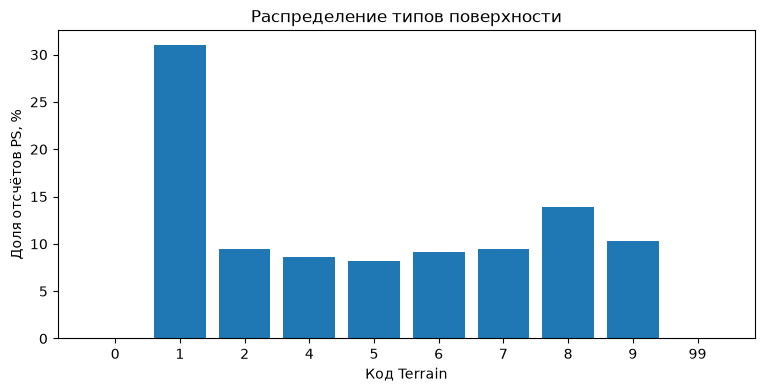

Самый частый код: 1
Коды менее чем у половины участников: [0, 99]


In [6]:
balance = terrain_counts.groupby("terrain").agg(
    samples=("samples", "sum"), participants=("participant", "nunique")
).sort_index()
balance["percent"] = (balance.samples / balance.samples.sum() * 100).round(1)
balance["name"] = [TERRAIN_NAMES.get(int(x), f"Неизвестный код {x}") for x in balance.index]
display(balance[["name", "samples", "percent", "participants"]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(balance.index.astype(str), balance.percent)
ax.set(xlabel="Код Terrain", ylabel="Доля отсчётов PS, %",
       title="Распределение типов поверхности")
plt.show()

print("Самый частый код:", balance.percent.idxmax())
print("Коды менее чем у половины участников:",
      balance.index[balance.participants < len(by_person) / 2].tolist())

Классы представлены неравномерно. Поэтому одной accuracy для оценки модели недостаточно: далее используются macro-F1, balanced accuracy, матрица ошибок и результаты по участникам.

## 4. Покрытие классов по участникам

Участники ходили по разным наборам поверхностей. Циклы одного человека нельзя случайно распределять между обучением и тестом: особенности его походки могут оказаться в обеих выборках.

terrain,0,Ровная поверхность,Трава,Лестница вверх,Лестница вниз,Подъём,Спуск,Код 8 (название спорное),Код 9 (название спорное),99
participant,,,,,,,,,,
P1,0,1,1,1,1,1,1,1,1,0
P10,0,1,1,1,1,1,1,1,1,0
P11,0,1,1,1,1,1,1,1,1,0
P12,0,1,1,1,1,1,1,1,1,0
P13,0,1,1,0,0,1,1,0,1,0
P14,0,1,1,1,1,1,1,1,0,0
P15,0,1,1,1,1,1,1,0,0,0
P16,0,1,1,1,1,1,1,0,0,0
P17,0,1,1,1,1,1,1,0,0,0


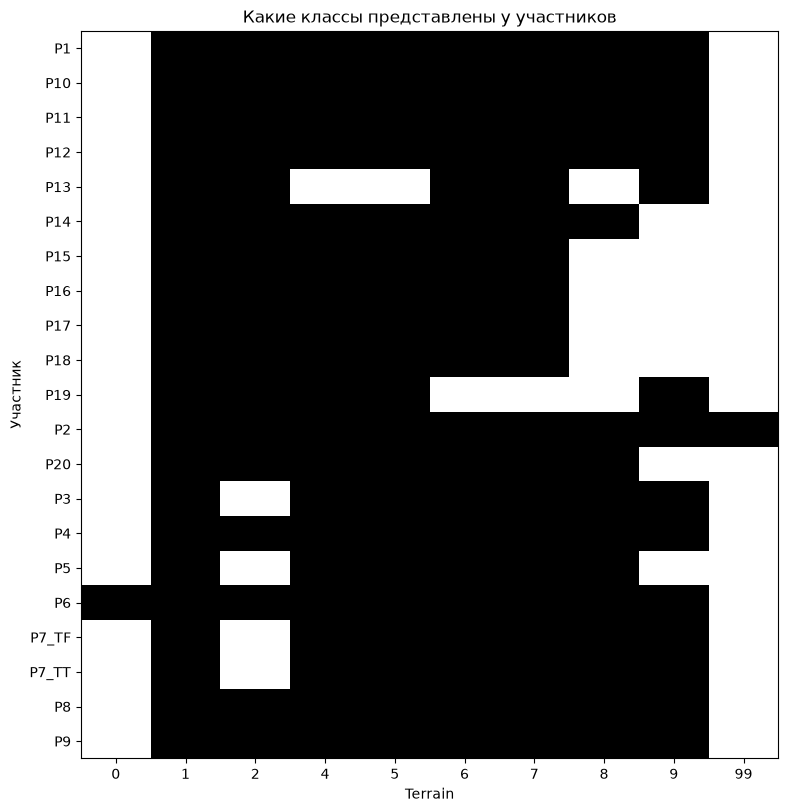

Участников с полным набором наблюдаемых классов: 0


In [7]:
coverage = terrain_counts.pivot_table(index="participant", columns="terrain",
                                      values="samples", aggfunc="sum", fill_value=0)
display((coverage > 0).astype(int).rename(columns=TERRAIN_NAMES))
fig, ax = plt.subplots(figsize=(9, max(3, len(coverage) * 0.45)))
ax.imshow(coverage > 0, aspect="auto", cmap="Greys")
ax.set_xticks(range(len(coverage.columns)), coverage.columns)
ax.set_yticks(range(len(coverage.index)), coverage.index)
ax.set(xlabel="Terrain", ylabel="Участник", title="Какие классы представлены у участников")
plt.show()
print("Участников с полным набором наблюдаемых классов:",
      int(((coverage > 0).sum(axis=1) == len(coverage.columns)).sum()))

Покрытие классов по людям различается. Для оценки на новом участнике нужны групповые разделения. Если в тестовой группе нет какого-то класса, ROC-AUC для всех классов не рассчитывается.

## 5. Длина размеченных циклов

`Steps` делит запись на циклы. Перед обучением проверяется их длина: длинный участок может содержать остановку или ошибку разметки. Длительность рассчитана при частоте 100 Гц, указанной в документации.

,Секунды
count,9789.000000
mean,1.400439
std,0.662245
min,0.250000
1%,0.500000
25%,1.220000
50%,1.340000
75%,1.490000
99%,2.941200
max,47.190000


Коротких сегментов (<0,4 с): 11
Длинных сегментов (>3 с): 87


,participant,trial,step,samples,duration_s,terrain,mixed_terrain,unknown_turn
38,P1,FL_wo_1,9,4719,47.19,1,False,False
5665,P4,SL_wo_2,38,1379,13.79,1,False,False
3257,P14,SL_wo_4,5,1145,11.45,6,False,False
341,P1,SL_wo_6,41,1134,11.34,1,False,False
4448,P2,SL_wo_5,32,972,9.72,1,False,False
7000,P6,UN_wi_2,40,911,9.11,1,False,False
449,P1,ST_wi_1,8,838,8.38,1,False,False
4447,P2,SL_wo_5,31,823,8.23,1,False,False
2794,P12,STEP_wi_1,10,812,8.12,1,False,False
5581,P4,SL_wo_1,38,783,7.83,1,False,False


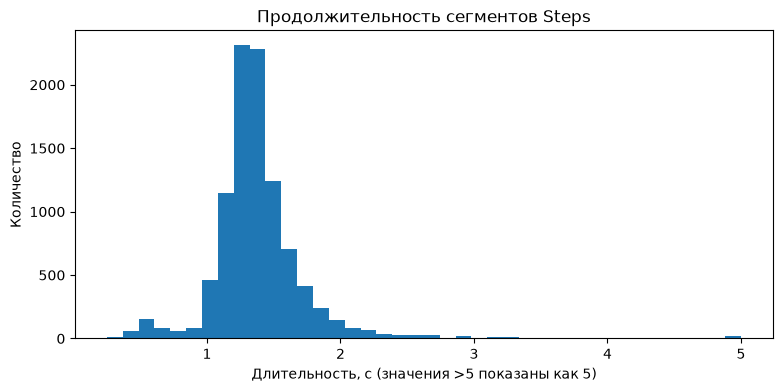

In [8]:
display(strides.duration_s.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame("Секунды"))
short = strides[strides.duration_s < 0.4]
long = strides[strides.duration_s > 3]
print(f"Коротких сегментов (<0,4 с): {len(short)}")
print(f"Длинных сегментов (>3 с): {len(long)}")
display(long.sort_values("duration_s", ascending=False).head(10))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(strides.duration_s.clip(upper=5), bins=40)
ax.set(xlabel="Длительность, с (значения >5 показаны как 5)",
       ylabel="Количество", title="Продолжительность сегментов Steps")
plt.show()

Среди циклов есть участок длиной около 47 секунд. По одной длительности нельзя определить его причину. Такие случаи требуют отдельной проверки сигнала и записи в журнале качества.

## 6. Масштаб сигналов P16

Отношение `VelInc` к `Acc` у P16 отличается от остальных участников. По CSV нельзя определить, связано ли это с экспортом данных или частотой записи.

,count,median,min,max
participant,,,,
P1,47,0.01000,0.01000,0.01043
P10,50,0.01000,0.01000,0.01051
P11,54,0.01000,0.01000,0.01018
P12,48,0.01000,0.01000,0.01000
P13,12,0.01000,0.01000,0.01000
P14,9,0.01000,0.01000,0.01000
P15,14,0.01000,0.01000,0.01000
P16,5,0.02500,0.02500,0.02500
P17,7,0.01000,0.01000,0.01000


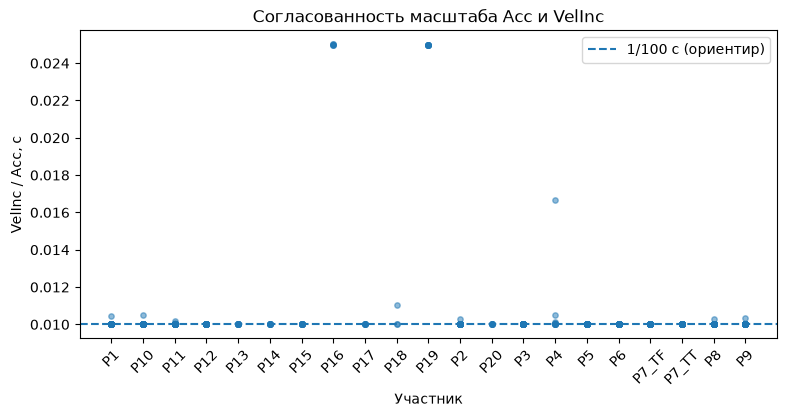

Медианный масштаб P16: 0.025


In [9]:
scale_summary = scales.groupby("participant").velinc_acc_scale.agg(
    ["count", "median", "min", "max"]
).sort_index()
display(scale_summary.round(5))
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(scales.participant, scales.velinc_acc_scale, alpha=.5, s=15)
ax.axhline(1 / FS, linestyle="--", label="1/100 с (ориентир)")
ax.set(xlabel="Участник", ylabel="VelInc / Acc, с",
       title="Согласованность масштаба Acc и VelInc")
ax.legend()
plt.xticks(rotation=45)
plt.show()
if "P16" in scale_summary.index:
    print("Медианный масштаб P16:", round(scale_summary.loc["P16", "median"], 5))

Отличие P16 подтверждает необходимость проверки масштаба `VelInc`. В первой модели этот канал не используется; влияние исключения P16 проверяется отдельно в ноутбуке 03.

## 7. Пример сигнала

Ниже показаны `Gyr_Y` датчика PS и метки поверхности на одном отрезке записи.

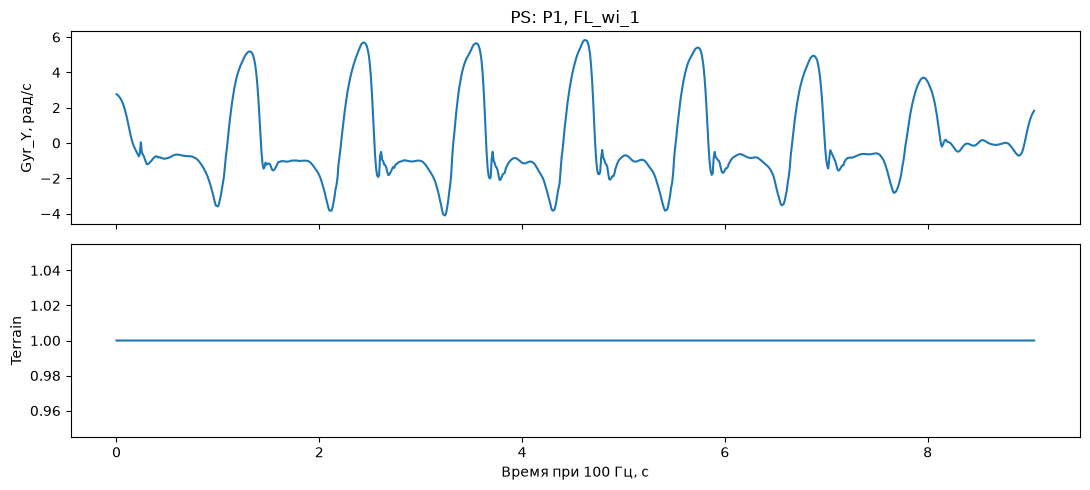

Показано отсчётов: 906 ; кодов Terrain: [1]


In [10]:
example_key = next(iter(ps_examples))
example = ps_examples[example_key]
length = min(len(example), 1500)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(np.arange(length) / FS, example.Gyr_Y.iloc[:length])
axes[0].set(ylabel="Gyr_Y, рад/с", title=f"PS: {example_key[0]}, {example_key[1]}")
axes[1].step(np.arange(length) / FS, example.Terrain.iloc[:length], where="post")
axes[1].set(xlabel="Время при 100 Гц, с", ylabel="Terrain")
plt.tight_layout()
plt.show()
print("Показано отсчётов:", length, "; кодов Terrain:", example.Terrain.iloc[:length].unique())

На графике виден меняющийся во времени сигнал. Для классификации он делится на циклы шага; `Terrain` используется как метка при обучении и оценке.

## 8. Итог

В данных есть совпадающие OS/TR-файлы, спорные названия кодов 8/9 и отдельные длинные циклы. Необычный масштаб P16 пока не объяснён. Эти особенности учитываются в следующих опытах без изменения исходных CSV.

Главная проверка модели — предсказание для участников, которые не встречались при обучении. В [следующем ноутбуке](02_reproduce_wassall_2026.ipynb) повторяется сравнение CV, LSO и LOPO из статьи Wassall et al.

## 9. Сохранение таблиц

Таблицы и рисунки уже находятся в выполненном ноутбуке. Для отдельного экспорта используется переменная `SAVE_ARTIFACTS` в начале файла. Экспорт не меняет исходные CSV.

In [11]:
if SAVE_ARTIFACTS:
    output_tables = OUTPUT_DIR / "tables"
    output_tables.mkdir(parents=True, exist_ok=True)
    for name, table in {
        "participants": by_person,
        "file_checks": checks.drop(columns="hash"),
        "terrain_balance": balance.reset_index(),
        "strides": strides,
        "velinc_acc_scale": scales,
        "os_tr_pairs": pairs,
    }.items():
        table.to_csv(output_tables / f"{name}.csv", index=False)
    print("Таблицы сохранены:", output_tables)
else:
    print("Сохранение отключено. Таблицы доступны в переменных ноутбука.")

Сохранение отключено. Таблицы доступны в переменных ноутбука.
